# 🚀 Fine-Tuning RF-DETR (Nano) for Custom Object Detection

Welcome to this tutorial notebook! In this guide, you will learn how to:
1. **Detect & utilize hardware acceleration** (NVIDIA CUDA, Apple Silicon MPS/Metal, or CPU fallback).
2. **Download a lightweight custom dataset** from Hugging Face (`keremberke/blood-cell-object-detection`).
3. **Initialize the smallest RF-DETR model** (`RFDETRNano`, ~30M params) using the official `rfdetr` library.
4. **Fine-tune the model** for a few epochs to validate training loss progression and metrics.
5. **Run inference and visualize predicted bounding boxes** with labels and confidence scores using `supervision`.

---


## Step 1: Environment & Accelerator Setup

RF-DETR is built on top of PyTorch and PyTorch Lightning. It natively supports:
- **NVIDIA GPUs** via `cuda`
- **Apple Silicon** via `mps` (Metal Performance Shaders / MLX hardware accelerator)
- **CPU** fallback

Let's inspect the environment and verify our available accelerator.


In [1]:
import importlib.metadata
import os
import torch
import rfdetr
from rfdetr import RFDETRNano

print(f"PyTorch version: {torch.__version__}")
try:
    rfdetr_ver = importlib.metadata.version("rfdetr")
    print(f"rfdetr version: {rfdetr_ver}")
except Exception:
    pass

# Intelligent accelerator detection
if torch.cuda.is_available():
    accelerator = "cuda"
    device_name = torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    accelerator = "mps"
    device_name = "Apple Silicon GPU (Metal / MPS)"
else:
    accelerator = "cpu"
    device_name = "CPU"

print(f"Active Accelerator: {accelerator.upper()} -> {device_name}")


PyTorch version: 2.10.0
rfdetr version: 1.10.1
Active Accelerator: MPS -> Apple Silicon GPU (Metal / MPS)


## Step 2: Download a Custom Dataset from Hugging Face

We will use `keremberke/blood-cell-object-detection` from Hugging Face.
This dataset has 3 classes:
- `platelets`
- `rbc` (Red Blood Cells)
- `wbc` (White Blood Cells)

RF-DETR natively understands Roboflow/COCO dataset directory layouts:
```
data/blood_cells/
├── train/
│   ├── _annotations.coco.json
│   └── *.jpg
└── valid/
    ├── _annotations.coco.json
    └── *.jpg
```

We download the dataset archive directly from Hugging Face Hub.


In [2]:
import json
import zipfile
from pathlib import Path
from huggingface_hub import hf_hub_download

DATASET_DIR = Path("./data/blood_cells")
DATASET_DIR.mkdir(parents=True, exist_ok=True)

# 1. Download train and validation splits from Hugging Face
print("Downloading dataset splits from Hugging Face Hub...")
train_zip_path = hf_hub_download(
    repo_id="keremberke/blood-cell-object-detection",
    filename="data/train.zip",
    repo_type="dataset"
)
valid_zip_path = hf_hub_download(
    repo_id="keremberke/blood-cell-object-detection",
    filename="data/valid-mini.zip",
    repo_type="dataset"
)

# 2. Extract into train and valid directories
train_dir = DATASET_DIR / "train"
valid_dir = DATASET_DIR / "valid"
train_dir.mkdir(parents=True, exist_ok=True)
valid_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(train_zip_path) as z:
    z.extractall(train_dir)

with zipfile.ZipFile(valid_zip_path) as z:
    z.extractall(valid_dir)

# Read categories from the COCO annotations
with open(train_dir / "_annotations.coco.json") as f:
    coco_meta = json.load(f)

categories = [cat["name"] for cat in sorted(coco_meta["categories"], key=lambda c: c["id"])]
print(f"Dataset downloaded and extracted!")
print(f"Target classes ({len(categories)}): {categories}")
print(f"Extracted train images: {len(list(train_dir.glob('*.jpg')))}")
print(f"Extracted valid images: {len(list(valid_dir.glob('*.jpg')))}")


Dataset downloaded and extracted!
Target classes (3): ['platelets', 'rbc', 'wbc']
Extracted train images: 255
Extracted valid images: 73


### Fast Tutorial Dataset Subset (Configurable)

To ensure this tutorial completes training in **under a minute** on any accelerator (CUDA or Apple Silicon MPS), we will train on a subset of 12 images. 

> *Tip: You can set `USE_FAST_SUBSET = False` whenever you wish to train on all 255 images for full accuracy.*


In [3]:
USE_FAST_SUBSET = True
SUBSET_SIZE = 12

if USE_FAST_SUBSET:
    with open(train_dir / "_annotations.coco.json") as f:
        coco_data = json.load(f)
    
    selected_images = coco_data["images"][:SUBSET_SIZE]
    selected_image_ids = {img["id"] for img in selected_images}
    selected_annotations = [ann for ann in coco_data["annotations"] if ann["image_id"] in selected_image_ids]
    
    fast_coco = {
        "images": selected_images,
        "annotations": selected_annotations,
        "categories": coco_data["categories"]
    }
    
    with open(train_dir / "_annotations.coco.json", "w") as f:
        json.dump(fast_coco, f, indent=2)
    
    print(f"Fast tutorial subset ready: {len(selected_images)} train images with {len(selected_annotations)} annotated objects.")
else:
    print("Using full training dataset.")


Fast tutorial subset ready: 12 train images with 160 annotated objects.


## Step 3: Visualize Ground Truth Annotations

Let's visualize an example image and its ground truth bounding boxes using `supervision` and `matplotlib`.


objc[73031]: Class AVFFrameReceiver is implemented in both /opt/miniconda3/envs/cv/lib/python3.10/site-packages/av/.dylibs/libavdevice.62.3.101.dylib (0x10b9203a8) and /opt/miniconda3/envs/cv/lib/python3.10/site-packages/cv2/.dylibs/libavdevice.61.3.100.dylib (0x1504b43a8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[73031]: Class AVFAudioReceiver is implemented in both /opt/miniconda3/envs/cv/lib/python3.10/site-packages/av/.dylibs/libavdevice.62.3.101.dylib (0x10b9203f8) and /opt/miniconda3/envs/cv/lib/python3.10/site-packages/cv2/.dylibs/libavdevice.61.3.100.dylib (0x1504b43f8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.


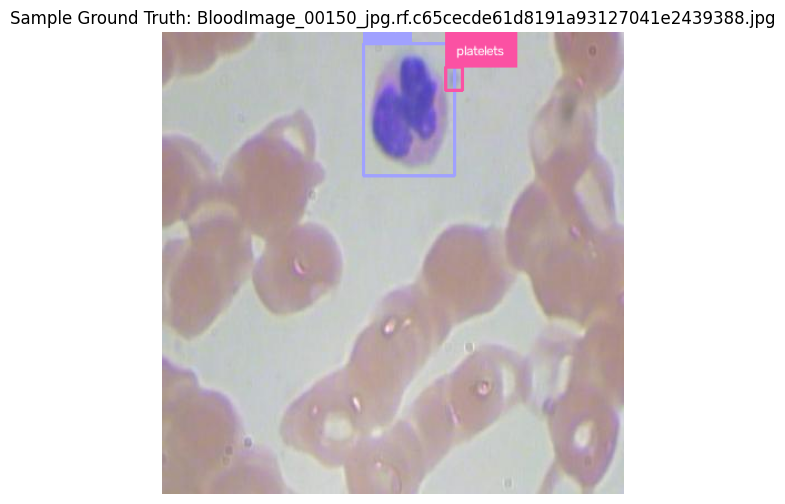

In [4]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import supervision as sv

# Load the first image and its annotations
with open(train_dir / "_annotations.coco.json") as f:
    coco_sample = json.load(f)

sample_img_info = coco_sample["images"][0]
sample_img_path = train_dir / sample_img_info["file_name"]
img_bgr = cv2.imread(str(sample_img_path))
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

img_anns = [ann for ann in coco_sample["annotations"] if ann["image_id"] == sample_img_info["id"]]
boxes = []
class_ids = []
for ann in img_anns:
    x, y, w, h = ann["bbox"]
    boxes.append([x, y, x + w, y + h])
    class_ids.append(ann["category_id"])

if boxes:
    detections = sv.Detections(
        xyxy=np.array(boxes, dtype=np.float32),
        class_id=np.array(class_ids, dtype=int)
    )
    
    box_annotator = sv.BoxAnnotator(thickness=2)
    label_annotator = sv.LabelAnnotator(text_scale=0.4, text_thickness=1)
    
    labels = [categories[cid] for cid in detections.class_id]
    annotated = box_annotator.annotate(scene=img_rgb.copy(), detections=detections)
    annotated = label_annotator.annotate(scene=annotated, detections=detections, labels=labels)
else:
    annotated = img_rgb

plt.figure(figsize=(6, 6))
plt.imshow(annotated)
plt.title(f"Sample Ground Truth: {sample_img_info['file_name']}")
plt.axis("off")
plt.show()


## Step 4: Initialize the Smallest Model (`RFDETRNano`)

`RFDETRNano` is the most lightweight model in the RF-DETR library:
- **Architecture**: Real-Time DEtection TRansformer with a distilled lightweight Vision Transformer backbone
- **Parameters**: ~30 Million
- **Advantage**: Fast convergence, high frame rate, and minimal memory footprint.

When first instantiated, the pre-trained weights are cached locally.


In [5]:
# Instantiate the smallest model
model = RFDETRNano()
print(f"Model initialized: {type(model).__name__}")


[2026-10-14 16:55:29] [INFO] rf-detr - File /Users/leonbora/.roboflow/models/rf-detr-nano.pth already exists with correct MD5 hash.


[2026-10-14 16:55:29] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-14 16:55:29] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-14 16:55:30] [INFO] rf-detr - File /Users/leonbora/.roboflow/models/rf-detr-nano.pth already exists with correct MD5 hash.


Model initialized: RFDETRNano


## Step 5: Fine-tune on Custom Dataset

We call `model.train()` to begin fine-tuning.

### Key Parameters:
- `dataset_dir`: Path containing `train/` and `valid/` directories.
- `epochs`: Number of epochs (3 epochs is sufficient to validate training progression).
- `batch_size`: Batch size per step (e.g. `2` or `4`).
- `num_workers`: Dataloader worker count (`0` ensures zero-issue compatibility across all operating systems).
- `output_dir`: Directory where checkpoints and training configurations are saved.
- `accelerator`: `"auto"` (automatically dispatches to CUDA, MPS, or CPU).
- `eval_interval`: Evaluates on the validation set every epoch to log mAP and loss.


In [6]:
OUTPUT_DIR = Path("./output/rfdetr_nano_bloodcells")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Train the model
model.train(
    dataset_dir=str(DATASET_DIR),
    epochs=3,
    batch_size=2,
    num_workers=0,
    output_dir=str(OUTPUT_DIR),
    accelerator="auto",
    eval_interval=1,
)
print("Training completed successfully!")


[2026-10-14 16:55:31] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-14 16:55:31] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-14 16:55:32] [INFO] rf-detr - File /Users/leonbora/.roboflow/models/rf-detr-nano.pth already exists with correct MD5 hash.


[2026-10-14 16:55:33] [WARNING] rf-detr - Checkpoint has 90 classes but model is configured for 3. The detection head will be re-initialized to 3 classes.


Using 16bit Automatic Mixed Precision (AMP)


...

[2026-10-14 16:55:53] [INFO] rf-detr - Best EMA metric improved to 0.4826 (epoch 1)


[2026-10-14 16:56:01] [INFO] rf-detr - Best EMA metric improved to 0.5188 (epoch 2)


`Trainer.fit` stopped: `max_epochs=3` reached.


[2026-10-14 16:56:02] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.5188)


Training completed successfully!


## Step 6: Verify Saved Checkpoints & Training Configuration

Let's check the output directory to verify that the best model checkpoint and config metadata were saved.


In [7]:
checkpoints = list(OUTPUT_DIR.glob("*.pth")) + list(OUTPUT_DIR.glob("*.ckpt"))
print(f"Checkpoints saved in {OUTPUT_DIR}:")
for ckpt in checkpoints:
    size_mb = ckpt.stat().st_size / (1024 * 1024)
    print(f" - {ckpt.name} ({size_mb:.2f} MB)")

config_path = OUTPUT_DIR / "training_config.json"
if config_path.exists():
    with open(config_path) as f:
        saved_cfg = json.load(f)
    print(f"Custom classes recorded: {saved_cfg.get('class_names')}")


Checkpoints saved in output/rfdetr_nano_bloodcells:
 - checkpoint_best_total.pth (115.29 MB)
 - last_ema.pth (115.29 MB)
 - checkpoint_best_ema.pth (115.29 MB)
 - last.ckpt (460.85 MB)
Custom classes recorded: ['platelets', 'rbc', 'wbc']


## Step 7: Run Inference & Visualize Predictions

We can now run object detection on a validation image using `model.predict()`.
`rfdetr` returns a `supervision.Detections` object that integrates seamlessly with `supervision` annotators for clean bounding box visualizations.


[2026-10-14 16:56:03] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Detections found: 44


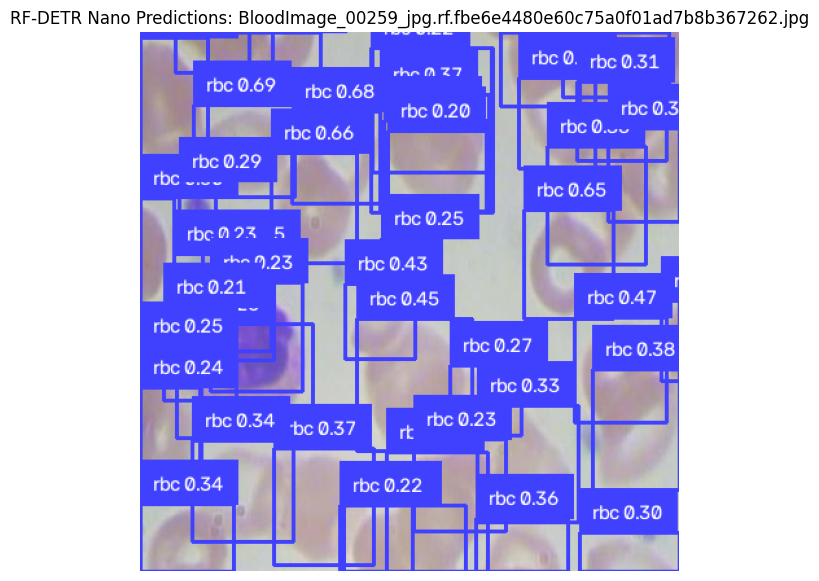

In [8]:
# Pick a validation image for testing
val_images = list(valid_dir.glob("*.jpg"))
test_image_path = str(val_images[0])

# Predict with confidence threshold 0.20
detections = model.predict(test_image_path, threshold=0.20)
print(f"Detections found: {len(detections.xyxy)}")

# Visualize with Supervision
test_bgr = cv2.imread(test_image_path)
test_rgb = cv2.cvtColor(test_bgr, cv2.COLOR_BGR2RGB)

box_annotator = sv.BoxAnnotator(thickness=2)
label_annotator = sv.LabelAnnotator(text_scale=0.5, text_thickness=1)

# Extract predicted class names and confidence scores
pred_names = detections.data.get("class_name", [])
labels = [
    f"{name} {conf:.2f}"
    for name, conf in zip(pred_names, detections.confidence)
]

annotated_test = box_annotator.annotate(scene=test_rgb.copy(), detections=detections)
annotated_test = label_annotator.annotate(scene=annotated_test, detections=detections, labels=labels)

plt.figure(figsize=(7, 7))
plt.imshow(annotated_test)
plt.title(f"RF-DETR Nano Predictions: {Path(test_image_path).name}")
plt.axis("off")
plt.show()


## Summary & Next Steps

🎉 You have successfully:
1. Checked your hardware accelerator (`cuda` on NVIDIA, `mps` on Apple Silicon, or `cpu`).
2. Downloaded and prepared a custom Hugging Face dataset in COCO/Roboflow format.
3. Fine-tuned the lightweight **RF-DETR Nano** model.
4. Monitored validation metrics and verified saved checkpoints.
5. Ran inference and visualized detected custom classes with confidence scores!

### Next Steps:
- **Train Longer**: Increase `epochs=25` or more with `USE_FAST_SUBSET = False` for production-grade mAP.
- **Larger Variants**: Try `RFDETRSmall()`, `RFDETRMedium()`, or `RFDETRBase()` for higher accuracy.
- **Exporting**: Export to ONNX or TensorRT using `model.export(format="onnx")`.
